# Chan et al. 2021 — Lung (SCLC) · 02 Manifold

Score the three embryonic modules (Gast/pSom/Crest) with the union control pool → graph-smooth for
the geography read → cell-cycle confound check → **honest topology test** (PPT tree fork-count) →
fit a **curve** (non-branching) with a fold diagnostic → root from the developmental order →
pseudotime. The PPT tree sprays spurious forks over the compact cloud (no dominant Y) and Gast/pSom
**co-vary** rather than compete, so the geometry is **non-branching (Linear)** and a curve is the
correct model — this directly addresses the re-run's branching concern.

In [1]:
import os, sys, glob, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr
sc.settings.verbosity = 1
name = os.path.split(os.getcwd())[1]
pth = os.path.join('..', '..', '..', '..')
pth_data = os.path.join(pth,'data')
pth_in  = os.path.join(pth_data,'cancer', 'vertebrate', 'CCCA', 'claude','Lung',name)
pth_feat = os.path.join(pth_data,'features','biomart')
pth_fig = os.path.join(pth,'figures', 'mesencontext', 'claude','Lung',name)
pth_cb  = os.path.join(pth_fig,'colorbars'); os.makedirs(pth_cb, exist_ok=True)

### Load `processed.h5ad`

In [2]:
adata = sc.read_h5ad(os.path.join(pth_in,'processed.h5ad')); print(adata.n_obs,'cells')
# ensure trajectory is fit on the untouched harmony-UMAP, not the display orientation
adata.obsm['X_umap'] = adata.obsm['X_umap_lin'].copy()

50881 cells


### Score modules (union control pool) + graph-smooth for geography

Deliverable signature UMAPs (03) show **raw** per-cell scores; smoothing here only aids the
geography/correlation read.

In [3]:
fd = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
      for f in glob.glob(pth_feat+'/*.csv')}
nm = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
gref = fd['union'][fd['union'].isin(adata.var_names)]
for src,ser in fd.items():
    if src=='union': continue
    g = ser[ser.isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=nm[src], ctrl_as_ref=False, gene_pool=gref, random_state=1234)
    print(f'{nm[src]}: {g.size}/{ser.size} genes recovered')
A = adata.obsp['connectivities']; deg = np.asarray(A.sum(1)).ravel(); deg[deg==0]=1
for m in ['Gast','pSom','Crest']:
    adata.obs[m+'_sm'] = np.asarray(A@adata.obs[m].values).ravel()/deg
adata.obs['cc_num'] = adata.obs['cc'].astype(float)
print('module means (raw):', {m: round(float(adata.obs[m].mean()),3) for m in ['Gast','pSom','Crest']})

Crest: 104/104 genes recovered
pSom: 96/98 genes recovered
Gast: 80/81 genes recovered
module means (raw): {'Gast': 0.037, 'pSom': 0.111, 'Crest': -0.08}


### Module geography + cell-cycle confound (biology before geometry)

**Gast and pSom co-vary** (positive smoothed r) while both oppose Crest (pSom↔Crest strongly
negative) — an inverse terminal-Crest gradient, not a competitive Gast/pSom bifurcation. Modules are
**not** proliferation-confounded (|r| with the cycling score is small); the embryonic relationships
hold in non-cycling cells alone — the Gast↔pSom co-variation strengthens (+0.48→+0.59) and the
pSom↔Crest anti-correlation persists (−0.80→−0.77) — so the whole manifold is kept (no scoping).

In [4]:
S = adata.obs[['Gast_sm','pSom_sm','Crest_sm']].corr()
print('smoothed spatial correlations (all cells):'); print(S.round(3))
print('\nmodule vs cell-cycle (raw):')
for m in ['Gast','pSom','Crest']:
    print(f'  {m} vs cc: r={np.corrcoef(adata.obs[m],adata.obs.cc_num)[0,1]:+.3f}')
nc = adata[adata.obs.cell_cycle_phase=='Not cycling']
print(f'\nnon-cycling (n={nc.n_obs}) smoothed corr:'); print(nc.obs[['Gast_sm','pSom_sm','Crest_sm']].corr().round(3))

smoothed spatial correlations (all cells):
          Gast_sm  pSom_sm  Crest_sm
Gast_sm     1.000    0.477    -0.520
pSom_sm     0.477    1.000    -0.802
Crest_sm   -0.520   -0.802     1.000

module vs cell-cycle (raw):
  Gast vs cc: r=-0.156
  pSom vs cc: r=-0.004
  Crest vs cc: r=+0.016

non-cycling (n=29681) smoothed corr:
          Gast_sm  pSom_sm  Crest_sm
Gast_sm     1.000    0.585    -0.665
pSom_sm     0.585    1.000    -0.765
Crest_sm   -0.665   -0.765     1.000


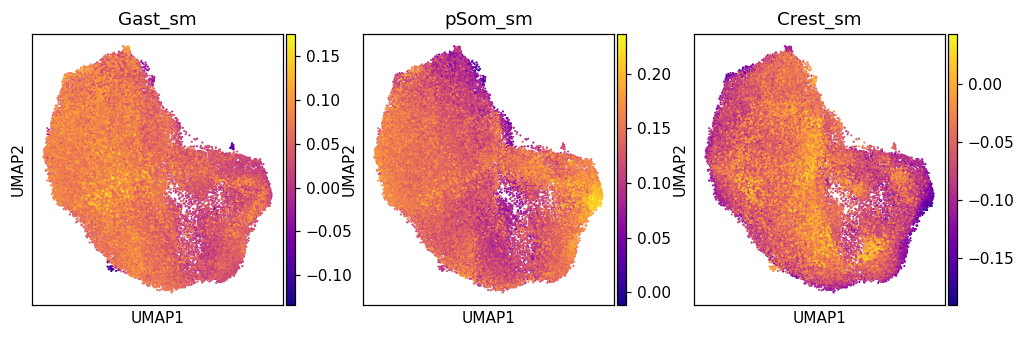

In [5]:
fig, axs = plt.subplots(1,3, figsize=(11,3.2))
for ax,m in zip(axs,['Gast_sm','pSom_sm','Crest_sm']):
    sc.pl.umap(adata, color=m, cmap='plasma', size=8, show=False, ax=ax); ax.set_title(m)
plt.show()

### Honest topology test — PPT tree fork count

A genuine bifurcation yields one dominant fork with two gradient-opposed arms. We fit a PPT **tree**
and count forks (nodes with degree ≥ 3). The tree either sprays many spurious forks over the compact
cloud or returns none — there is no single dominant Y — confirming the manifold is **non-branching**,
so a **curve** is the right model.

In [6]:
ad_t = adata.copy()
scf.tl.tree(ad_t, method='ppt', Nodes=100, ppt_lambda=2000, ppt_sigma=5,
            use_rep='X_umap', seed=1, plot=False, basis='umap')
B = ad_t.uns['graph']['B']; degv = B.sum(0)
print('PPT tree: nodes=%d  tips(deg1)=%d  forks(deg>=3)=%d' % (B.shape[0], int((degv==1).sum()), int((degv>=3).sum())))
print('=> no single dominant bifurcation -> non-branching -> fit a curve')

inferring a principal tree --> parameters used 
    100 principal points, sigma = 5, lambda = 2000, metric = euclidean
    fitting:  82%|########2 | 41/50 [00:04<00:00,  9.63it/s]
    converged
    finished (0:00:04) --> added 
    .uns['ppt'], dictionnary containing inferred tree.
    .obsm['X_R'] soft assignment of cells to principal points.
    .uns['graph']['B'] adjacency matrix of the principal points.
    .uns['graph']['F'] coordinates of principal points in representation space.
PPT tree: nodes=100  tips(deg1)=2  forks(deg>=3)=0
=> no single dominant bifurcation -> non-branching -> fit a curve


### Fit curve + fold diagnostic (no re-embedding of a linear compartment)

Elastic principal curve on the existing `X_umap`. The fold diagnostic — minimum Euclidean approach
between graph-distant nodes divided by the median edge length — is measured on the **fitted node
graph**, independent of the UMAP-neighbour graph. A ratio > 1 certifies a fold-free curve.

In [7]:
scf.tl.curve(adata, Nodes=30, use_rep='X_umap', epg_lambda=0.3, epg_mu=100, seed=1)
g = adata.uns['graph']; B = g['B']; F = g['F'].T; R = adata.obsm['X_R']
degv = B.sum(0); tips = np.where(degv==1)[0]
print('curve: nodes=%d tips=%s forks=%d' % (B.shape[0], tips.tolist(), int((degv>=3).sum())))
from scipy.sparse.csgraph import shortest_path
from scipy.spatial.distance import cdist
import scipy.sparse as sp
gd = shortest_path(sp.csr_matrix(B), method='D'); ed = cdist(F,F)
edge_len = np.median(ed[B>0])
far = gd > 3*np.median(gd[np.isfinite(gd)&(gd>0)])
ratio = (ed[far].min()/edge_len) if far.sum() else np.inf
print(f'fold diagnostic: min far-node approach / median edge = {ratio:.2f}  (>1 => fold-free)')

inferring a principal curve --> parameters used 
    30 principal points, mu = 100, lambda = 0.3
    finished (0:00:13) --> added 
    .uns['epg'] dictionnary containing inferred elastic curve generated from elpigraph.
    .obsm['X_R'] soft assignment of cells to principal points.
    .uns['graph']['B'] adjacency matrix of the principal points.
    .uns['graph']['F'], coordinates of principal points in representation space.
curve: nodes=30 tips=[0, 2] forks=0
fold diagnostic: min far-node approach / median edge = 24.67  (>1 => fold-free)


### Root from developmental order (Crest is *late*, never the root)

Score each curve tip's neighbourhood on `Gast + pSom − Crest` and root at the argmax — the
Gast/pSom-high, Crest-low developmental origin.

In [8]:
node_score = (R.T @ (adata.obs.Gast.values+adata.obs.pSom.values-adata.obs.Crest.values))/(R.sum(0)+1e-9)
tip_scores = {int(t): float(node_score[t]) for t in tips}
print('tip developmental scores (Gast+pSom-Crest):', {k:round(v,3) for k,v in tip_scores.items()})
root = int(max(tip_scores, key=tip_scores.get)); print('ROOT node =', root)
scf.tl.root(adata, root)
scf.tl.pseudotime(adata, seed=1)
q = pd.qcut(adata.obs['t'], 3, labels=['early','mid','late'])
print('\nmodule means by pseudotime tercile (root validation):')
print(adata.obs.groupby(q, observed=True)[['Gast','pSom','Crest']].mean().round(3))

tip developmental scores (Gast+pSom-Crest): {0: 0.225, 2: 0.252}
ROOT node = 2
node 2 selected as a root --> added
    .uns['graph']['root'] selected root.
    .uns['graph']['pp_info'] for each PP, its distance vs root and segment assignment.
    .uns['graph']['pp_seg'] segments network information.
projecting cells onto the principal graph
    finished (0:00:41) --> added
    .obs['edge'] assigned edge.
    .obs['t'] pseudotime value.
    .obs['seg'] segment of the tree assigned.
    .obs['milestones'] milestone assigned.
    .uns['pseudotime_list'] list of cell projection from all mappings.

module means by pseudotime tercile (root validation):
        Gast   pSom  Crest
t                         
early  0.022  0.114 -0.083
mid    0.045  0.111 -0.075
late   0.042  0.109 -0.082


In [9]:
# rename milestones by pseudotime order: Origin -> Terminus
t_ms = adata.obs.groupby('milestones', observed=True)['t'].mean().sort_values()
order = t_ms.index.tolist()
newn = {order[0]:'Origin', order[-1]:'Terminus'}
for i,m in enumerate(order[1:-1],1): newn[m]=f'Mid{i}'
scf.tl.rename_milestones(adata, new=newn)
print('milestones (pseudotime order):', [(newn[m], round(float(t_ms[m]),2)) for m in order])

milestones (pseudotime order): [('Origin', 2.66), ('Terminus', 11.05)]


### Save `manifold.h5ad` + deliverable `manifold.pdf` (pseudotime + curve edges, house orientation)

In [10]:
adata.uns.pop('epg', None)
adata.write(os.path.join(pth_in,'manifold.h5ad')); print('saved manifold.h5ad')

saved manifold.h5ad


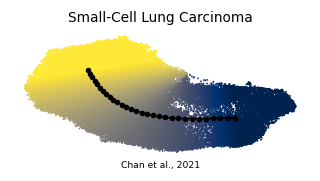

In [11]:
# curve node coords are already in the X_umap (=X_umap_lin) orientation used for the fit
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, color='t', cmap='cividis', size=6, colorbar_loc=None, frameon=False, show=False, ax=ax)
ii,jj = np.where(np.triu(B>0))
for a,b in zip(ii,jj):
    ax.plot([F[a,0],F[b,0]],[F[a,1],F[b,1]], '-', color='k', lw=1.0, zorder=5)
ax.scatter(F[:,0],F[:,1], s=7, color='k', zorder=6)
ax.set_title('Small-Cell Lung Carcinoma', size=9)
ax.text(.5,-.08,'Chan et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight'); plt.show()